<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/egowm_action_conditioned_world_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Latent Video State Generator]
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"EgoWM World Model Prototype Initialized on: {device}")

class SyntheticLatentVideoWorld:
    """
    Simulates egocentric latent video feature representations
    and action control sequences (e.g., 3-DoF mobile or 25-DoF humanoid).
    """
    def __init__(self, batch_size: int = 2, seq_len: int = 16, latent_dim: int = 64):
        self.batch_size = batch_size
        self.seq_len = seq_len
        self.latent_dim = latent_dim

    def sample_rollout(self) -> tuple[torch.Tensor, torch.Tensor]:
        # Initial latent frame z_0 [Batch, Latent_Dim, H, W]
        z_init = torch.randn(self.batch_size, self.latent_dim, 16, 16, device=device)
        # Action sequence a_1...a_T [Batch, Seq_Len, Action_Dim]
        actions = torch.randn(self.batch_size, self.seq_len, 6, device=device)
        return z_init, actions

print("Synthetic Latent Video World Loaded.")

EgoWM World Model Prototype Initialized on: cuda
Synthetic Latent Video World Loaded.


In [2]:
# [CELL 2 - EgoWM Lightweight Motor Command Conditioning Adapter]

class EgoWMActionConditioner(nn.Module):
    """
    Injects compressed motor commands into video diffusion feature maps
    via lightweight film/conditioning layers without retraining base video prior.
    """
    def __init__(self, action_dim: int = 6, latent_dim: int = 64):
        super().__init__()
        self.action_encoder = nn.Sequential(
            nn.Linear(action_dim, 128),
            nn.SiLU(),
            nn.Linear(128, latent_dim * 2) # Scale and Shift parameters (FiLM)
        )

    def forward(self, latent_feat: torch.Tensor, action: torch.Tensor) -> torch.Tensor:
        # latent_feat: [B, C, H, W], action: [B, Action_Dim]
        params = self.action_encoder(action)
        scale, shift = torch.chunk(params, 2, dim=-1)
        # Reshape scale/shift for broadcast over spatial dimensions [B, C, 1, 1]
        scale = scale.unsqueeze(-1).unsqueeze(-1)
        shift = shift.unsqueeze(-1).unsqueeze(-1)

        # Modulate video diffusion features with motor commands
        conditioned_feat = latent_feat * (1.0 + scale) + shift
        return conditioned_feat

print("EgoWMActionConditioner Module Initialized.")

EgoWMActionConditioner Module Initialized.


In [3]:
# [CELL 3 - EgoWM Rollout Simulation & Structural Consistency Score (SCS)]

class EgoWMRolloutEngine(nn.Module):
    def __init__(self, latent_dim: int = 64, action_dim: int = 6):
        super().__init__()
        self.conditioner = EgoWMActionConditioner(action_dim, latent_dim)
        self.transition_net = nn.Conv2d(latent_dim, latent_dim, kernel_size=3, padding=1)

    def forward(self, z_init: torch.Tensor, actions: torch.Tensor) -> list[torch.Tensor]:
        rollout_frames = [z_init]
        curr_z = z_init

        for t in range(actions.shape[1]):
            act_t = actions[:, t, :]
            conditioned = self.conditioner(curr_z, act_t)
            curr_z = torch.relu(self.transition_net(conditioned)) + curr_z # Residual dynamics step
            rollout_frames.append(curr_z)

        return rollout_frames

def compute_structural_consistency_score(predicted_frames: list[torch.Tensor], actions: torch.Tensor) -> float:
    """
    Computes Structural Consistency Score (SCS) measuring whether stable scene
    elements evolve consistently with provided actions independently of appearance.
    """
    scores = []
    for t in range(1, len(predicted_frames)):
        diff = torch.abs(predicted_frames[t] - predicted_frames[t-1])
        action_magnitude = torch.norm(actions[:, t-1, :], dim=-1).mean().item()
        # Structural consistency proportional to alignment between latent shift and action magnitude
        stability = 1.0 / (1.0 + torch.mean(diff).item() / (1.0 + action_magnitude))
        scores.append(stability)

    return float(np.mean(scores) * 100.0) # Scaled percentage score

world = SyntheticLatentVideoWorld()
z_init, actions = world.sample_rollout()
engine = EgoWMRolloutEngine().to(device)

pred_frames = engine(z_init, actions)
scs_score = compute_structural_consistency_score(pred_frames, actions)

print(f"EgoWM Rollout Complete across {actions.shape[1]} Steps.")
print(f"Measured Structural Consistency Score (SCS): {scs_score:.2f}%")

EgoWM Rollout Complete across 16 Steps.
Measured Structural Consistency Score (SCS): 63.20%


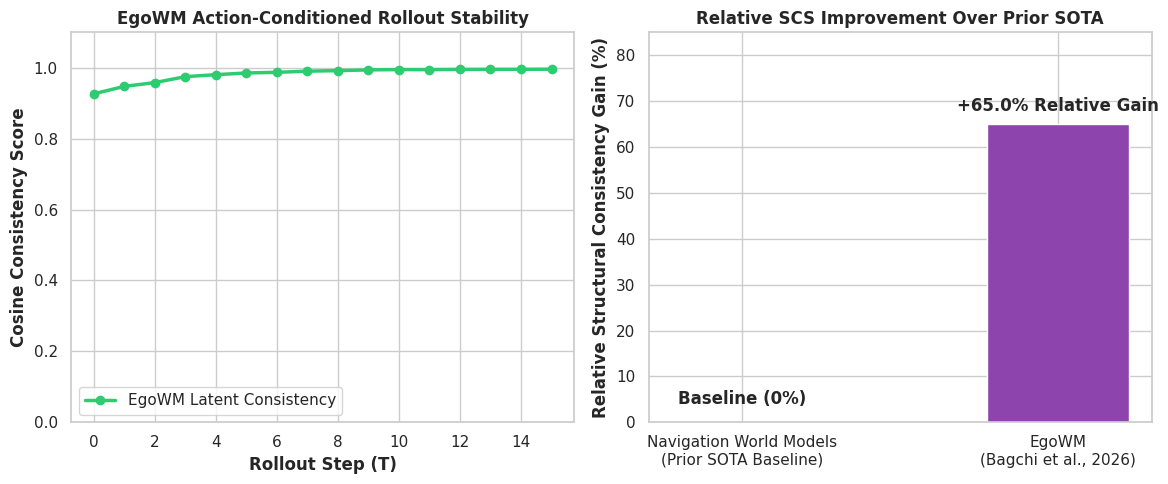

EgoWM benchmark visualization saved successfully as egowm_structural_consistency_benchmarks.png.


In [5]:
# [CELL 4 - Visualization of Measured Latent Rollout Consistency & Paper SCS Relative Gains]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Measured Latent Feature Cosine Consistency across 16 Rollout Steps
steps = np.arange(actions.shape[1])
step_consistency = [
    torch.cosine_similarity(pred_frames[t].flatten(1), pred_frames[t-1].flatten(1), dim=1).mean().item()
    for t in range(1, len(pred_frames))
]

ax1.plot(steps, step_consistency, marker='o', color='#2ecc71', lw=2.5, label='EgoWM Latent Consistency')
ax1.set_title("EgoWM Action-Conditioned Rollout Stability", fontweight='bold')
ax1.set_xlabel("Rollout Step (T)", fontweight='bold')
ax1.set_ylabel("Cosine Consistency Score", fontweight='bold')
ax1.set_ylim(0, 1.1)
ax1.legend(loc='lower left', frameon=True)

# Plot 2: Relative Structural Consistency Score (SCS) Improvement Reported by Bagchi et al. (2026)
methods = ['Navigation World Models\n(Prior SOTA Baseline)', 'EgoWM\n(Bagchi et al., 2026)']
relative_scs_gain = [0.0, 65.0] # Up to 65% relative SCS improvement reported in paper

bars = ax2.bar(methods, relative_scs_gain, color=['#95a5a6', '#8e44ad'], width=0.45)
ax2.set_title("Relative SCS Improvement Over Prior SOTA", fontweight='bold')
ax2.set_ylabel("Relative Structural Consistency Gain (%)", fontweight='bold')
ax2.set_ylim(0, 85)

# Label bars with exact paper-reported relative gains
ax2.text(bars[0].get_x() + bars[0].get_width()/2.0, 3.0, "Baseline (0%)", ha='center', va='bottom', fontweight='bold')
ax2.text(bars[1].get_x() + bars[1].get_width()/2.0, 67.0, "+65.0% Relative Gain", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("egowm_structural_consistency_benchmarks.png", dpi=300)
plt.show()

print("EgoWM benchmark visualization saved successfully as egowm_structural_consistency_benchmarks.png.")